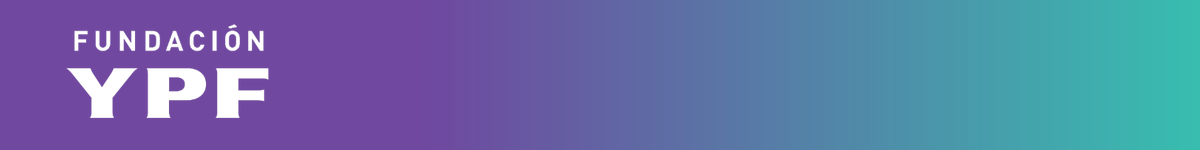

# Fundación YPF - Data Science

## Notebook 32: Práctica integradora de Redes Neuronales

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso de conceptos: de la neurona al perceptrón multicapa
* **Parte 2:** Carga y exploración del dataset
* **Parte 3:** Preprocesamiento para la red neuronal
* **Parte 4:** Entrenamos un MLPClassifier
* **Parte 5:** Evaluación del modelo
* **Parte 6:** Función de activación y regularización: comparamos variantes
* **Parte 7:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En las clases 25 a 27 (Notebooks 29 a 31) vimos la teoría de redes neuronales: la neurona y el perceptrón simple, el descenso por gradiente, la entropía cruzada, forward y back propagation, el perceptrón multicapa, las funciones de activación y la regularización. Esta es la clase práctica de cierre del módulo: aplicamos todo eso de punta a punta, entrenando y evaluando una red neuronal con scikit-learn.

**Datasets:**

* `cancer_mamario.csv`: datos clínicos de pacientes con cáncer de mama, con la variable `class` que indica si hubo recurrencia o no. Lo usamos en la parte guiada para armar una red neuronal de clasificación binaria.
* `StudentsPerformance.csv`: puntajes de estudiantes en matemática, lectura y escritura. Lo usamos en el ejercicio de las salas para repetir el proceso con un dataset nuevo.

Antes de ejecutar, subí los archivos `cancer_mamario.csv` y `StudentsPerformance.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso de conceptos: de la neurona al perceptrón multicapa

* **Neurona:** combina las entradas con sus pesos (unión sumadora) y aplica una **función de activación**. El perceptrón simple es una sola neurona con activación sigmoidea, que devuelve una probabilidad entre 0 y 1.
* **Función de costo:** mide qué tan lejos están las predicciones de las etiquetas reales. Para clasificación se usa la **entropía cruzada**.
* **Descenso por gradiente:** algoritmo que ajusta los pesos en la dirección que más reduce el costo, paso a paso, hasta converger a un mínimo.
* **Forward propagation:** con los pesos actuales, calculamos la predicción y el costo para las instancias de entrada.
* **Backpropagation:** derivamos el costo respecto de cada peso (de salida hacia entrada) y actualizamos los pesos con descenso por gradiente.
* **Perceptrón multicapa (MLP):** varias neuronas organizadas en capas. Cada neurona tiene sus propios pesos, y los mismos conceptos (forward, costo, backpropagation, descenso por gradiente) se aplican capa por capa.
* **Funciones de activación:** sigmoidea, tanh y ReLU son las más usadas. Cada una tiene ventajas y problemas distintos (por ejemplo, el vanishing gradient de sigmoidea y tanh).
* **Regularización:** técnicas como la penalización L2 de los pesos o el dropout, que buscan evitar que la red memorice los datos de entrenamiento (overfitting).

En scikit-learn, todo esto está implementado en `MLPClassifier`: nosotros elegimos la arquitectura (cantidad de capas y neuronas) y los hiperparámetros, y la librería se encarga de correr el descenso por gradiente con forward y back propagation.

## Parte 2: Carga y exploración del dataset

Usamos `cancer_mamario.csv`. Cada fila es una paciente, con variables clínicas categóricas (edad por rango, menopausia, tamaño del tumor, etc.) y la variable `class`, que indica si hubo recurrencia del cáncer o no.

In [2]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

cancer = pd.read_csv("cancer_mamario.csv")
print("Filas y columnas:", cancer.shape)
cancer.head()

Filas y columnas: (286, 10)


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64


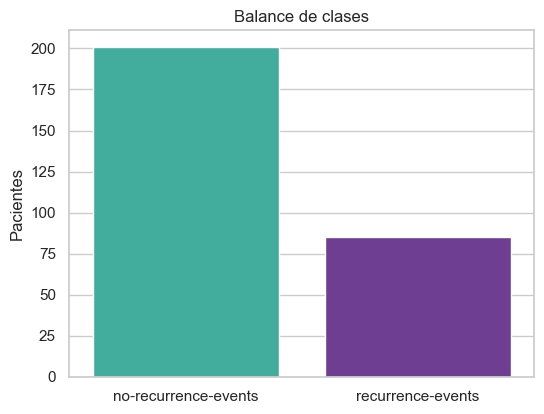

In [3]:
print(cancer["class"].value_counts())

plt.figure(figsize=(6, 4.5))
sns.countplot(data=cancer, x="class", hue="class", palette=["#30BEAA", "#7030A0"], legend=False)
plt.xlabel("")
plt.ylabel("Pacientes")
plt.title("Balance de clases")
plt.show()

De las 286 pacientes, 201 (70%) no tuvieron recurrencia y 85 (30%) sí. Es un dataset desbalanceado: hay que tenerlo en cuenta al mirar las métricas por clase, no solo la exactitud global.

## Parte 3: Preprocesamiento para la red neuronal

Una red neuronal necesita entradas numéricas y en una escala comparable, así que antes de entrenar:

1. Sacamos las filas con valores faltantes (marcados con `?` en `node-caps` y `breast-quad`).
2. Convertimos la variable `class` en 0 (sin recurrencia) y 1 (recurrencia).
3. Convertimos las variables categóricas a columnas numéricas con one-hot encoding (`pd.get_dummies`).
4. Separamos en entrenamiento y prueba.
5. Escalamos las variables numéricas con `StandardScaler`, ajustado solo con el conjunto de entrenamiento.

In [4]:
filas_antes = len(cancer)
cancer_limpio = cancer[(cancer != "?").all(axis=1)].copy()
print(f"Filas antes de sacar los '?': {filas_antes}. Filas después: {len(cancer_limpio)}")

cancer_limpio["target"] = (cancer_limpio["class"] == "recurrence-events").astype(int)

columnas_categoricas = ["age", "menopause", "tumor-size", "inv-nodes", "node-caps",
                         "breast", "breast-quad", "irradiat"]
X = pd.get_dummies(cancer_limpio[columnas_categoricas + ["deg-malig"]], columns=columnas_categoricas)
y = cancer_limpio["target"]
print("Features después del one-hot encoding:", X.shape[1])

Filas antes de sacar los '?': 286. Filas después: 277
Features después del one-hot encoding: 39


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("Entrenamiento:", X_train_esc.shape, "Prueba:", X_test_esc.shape)

Entrenamiento: (207, 39) Prueba: (70, 39)


## Parte 4: Entrenamos un MLPClassifier

Armamos un perceptrón multicapa con dos capas ocultas (16 y 8 neuronas) y activación ReLU. `MLPClassifier` entrena con descenso por gradiente (forward propagation para predecir, entropía cruzada como función de costo, backpropagation para actualizar los pesos), exactamente lo que repasamos en la Parte 1.

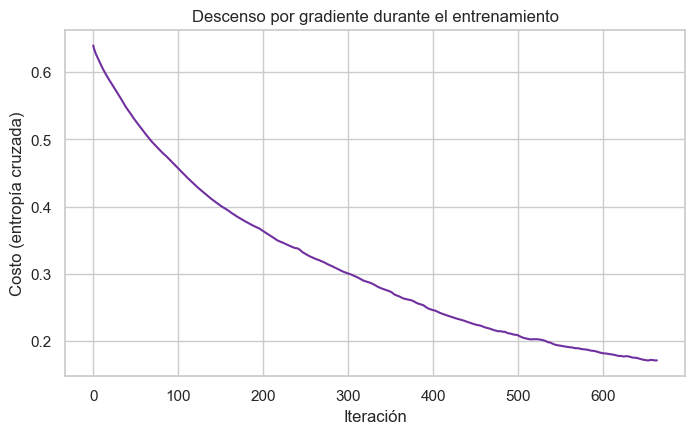

Cantidad de iteraciones hasta converger: 664


In [6]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_esc, y_train)

plt.figure(figsize=(8, 4.5))
plt.plot(mlp.loss_curve_, color="#7030A0")
plt.xlabel("Iteración")
plt.ylabel("Costo (entropía cruzada)")
plt.title("Descenso por gradiente durante el entrenamiento")
plt.show()

print(f"Cantidad de iteraciones hasta converger: {mlp.n_iter_}")

El costo baja de manera sostenida a medida que avanzan las iteraciones y se aplana hacia el final: así se ve el descenso por gradiente funcionando. El entrenamiento convergió en 664 iteraciones, antes del máximo de 1000 que le permitimos.

## Parte 5: Evaluación del modelo

Medimos qué tan bien generaliza la red a pacientes que no vio durante el entrenamiento, con el conjunto de prueba.

Exactitud en prueba: 0.700

                 precision    recall  f1-score   support

sin recurrencia       0.78      0.80      0.79        50
    recurrencia       0.47      0.45      0.46        20

       accuracy                           0.70        70
      macro avg       0.63      0.62      0.63        70
   weighted avg       0.70      0.70      0.70        70



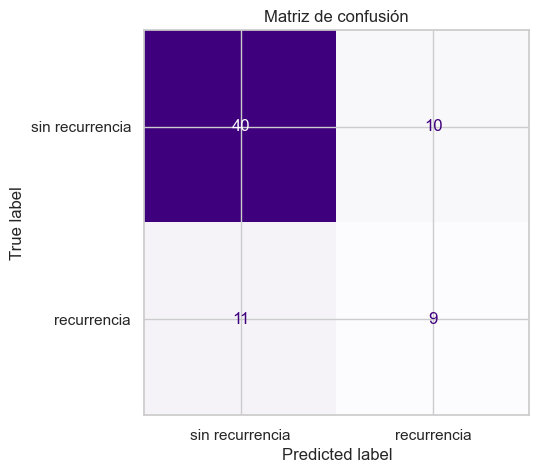

In [7]:
y_pred = mlp.predict(X_test_esc)

exactitud = accuracy_score(y_test, y_pred)
print(f"Exactitud en prueba: {exactitud:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["sin recurrencia", "recurrencia"]))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=["sin recurrencia", "recurrencia"]).plot(ax=ax, cmap="Purples", colorbar=False)
plt.title("Matriz de confusión")
plt.show()

La red logra una exactitud de 0.700 en el conjunto de prueba. Clasifica bastante bien a las pacientes sin recurrencia (precisión 0.78, recall 0.80: 40 de 50 bien clasificadas), pero le cuesta más la clase minoritaria: de las 20 pacientes con recurrencia, identifica correctamente a 9 (recall 0.45) y confunde 11 con la clase sin recurrencia. Esto es consistente con el desbalance de clases que vimos en la Parte 2: con pocos ejemplos de recurrencia, la red tiende a favorecer la clase mayoritaria.

## Parte 6: Función de activación y regularización: comparamos variantes

En la clase 27 vimos que sigmoidea, tanh y ReLU tienen comportamientos distintos, y que la regularización L2 penaliza pesos grandes para evitar overfitting. Entrenamos variantes del mismo MLP cambiando la función de activación y el parámetro de regularización `alpha`, y comparamos la exactitud en el conjunto de prueba.

In [8]:
resultados = []
for activacion in ["relu", "tanh", "logistic"]:
    for alpha in [0.0001, 0.01]:
        modelo = MLPClassifier(
            hidden_layer_sizes=(16, 8),
            activation=activacion,
            alpha=alpha,
            solver="adam",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )
        modelo.fit(X_train_esc, y_train)
        pred = modelo.predict(X_test_esc)
        resultados.append({
            "activacion": activacion,
            "alpha": alpha,
            "exactitud_test": accuracy_score(y_test, pred),
        })

comparacion = pd.DataFrame(resultados).sort_values("exactitud_test", ascending=False).reset_index(drop=True)
comparacion

,activacion,alpha,exactitud_test
0,relu,0.0001,0.700000
1,relu,0.0100,0.700000
2,tanh,0.0001,0.671429
3,logistic,0.0001,0.671429
4,tanh,0.0100,0.657143
5,logistic,0.0100,0.642857


La combinación relu con alpha=0.0001 (la que usamos en la Parte 4) y relu con alpha=0.01 quedan primeras, ambas con exactitud 0.700. tanh y logistic (sigmoidea) rinden un poco peor (entre 0.643 y 0.671) en este dataset. Subir la regularización (alpha) no mejora el resultado acá: con un dataset chico como este, el problema principal es el desbalance de clases, no el overfitting de los pesos.

## Parte 7: Ejercicio para las salas de Zoom

**Dataset:** `StudentsPerformance.csv`. Tiene los puntajes de 1000 estudiantes en matemática (escala 0 a 10), lectura y escritura (escala 0 a 100), y variables personales (género, grupo étnico, nivel educativo de los padres, tipo de almuerzo, si hizo el curso de preparación).

**Contexto:** van a repetir el proceso completo que hicimos en las Partes 2 a 6, pero con un problema de clasificación nuevo: predecir si un estudiante aprueba o no, a partir de sus características personales (sin usar los puntajes como entrada, porque el objetivo es predecir el resultado antes de verlo).

In [9]:
# Cargamos el dataset del ejercicio
if not os.path.exists("StudentsPerformance.csv"):
    from google.colab import files
    files.upload()

estudiantes = pd.read_csv("StudentsPerformance.csv").drop(columns=["Unnamed: 0"])

# El puntaje de matemática está en escala 0-10 y los de lectura/escritura en 0-100.
# Llevamos los tres a una escala comparable (0-100) para construir el promedio.
estudiantes["promedio"] = (estudiantes["math score"] * 10 + estudiantes["reading score"] + estudiantes["writing score"]) / 3
estudiantes.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,promedio
0,female,group B,bachelor's degree,standard,none,7.2,72,74,72.666667
1,female,group C,some college,standard,completed,6.9,90,88,82.333333
2,female,group B,master's degree,standard,none,9.0,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,4.7,57,44,49.333333
4,male,group C,some college,standard,none,7.6,78,75,76.333333


In [10]:
# 1. Construir la variable objetivo: "aprobado" = 1 si promedio >= 60, 0 si no.
# COMPLETAR

In [11]:
# 2. Explorar el dataset: tipos de datos, valores faltantes y balance de clases de "aprobado".
# COMPLETAR

In [12]:
# 3. Preprocesamiento: one-hot encoding de las variables categóricas (sin usar los puntajes ni "promedio" como feature), train/test split estratificado y escalado con StandardScaler.
# COMPLETAR

In [13]:
# 4. Entrenar un MLPClassifier con los datos preprocesados y graficar la curva de costo (loss_curve_).
# COMPLETAR

In [14]:
# 5. Evaluar el modelo: exactitud, classification_report y matriz de confusión sobre el conjunto de prueba.
# COMPLETAR

In [15]:
# 6. Comparar al menos dos funciones de activación (por ejemplo relu y tanh) y discutir cuál generaliza mejor.
# COMPLETAR